# AST 326: Asteroid Lab 
### Tutorial 2 - How to Find the Source Positions
- Primary Authors: Jacob Taylor, Bethany Ludwig
- Last Revision: January 2024
  
### Overview of the Lab:  

The goal of this lab is to measure the proper motion of an asteroid using 4 observations. To do this, we will first need to determine the asteroids position in each observation using astrometry. If you'd like a head start, feel free to practice on the NGC7331 galaxy. 

This lab is broken into four tutorials: 

1) Familiarize yourself with the data and how to obtain clean sky images (Last Week)

2) Find stars in your cleaned images and cross correlate them with a catalog (Today)

3) Plate solve your images and compute asteroid positions (Jan 22)
  
4) Decomposing affine transformations (optional part of the lab) and open work session (Jan 29)

### Step 1: Import your centroids from the last tutorial and the USNO catalog. 

In [48]:
# We'll use pandas to help manage these catalog 
import pandas as pd

# Set the path to the centroid catalog we want to use
my_catalog_path = 'Data/26Proserpina/Centroids/20120119.csv'

# Import the catalog 
df = pd.read_csv(my_catalog_path)

# View the first few rows
df.head()

,x,y
0,56.500570,29.500593
1,117.501245,23.499652
2,77.501231,157.500363
3,194.502072,170.505295
4,125.501442,190.500058


In [49]:
# The USNO catalog is a catalog of local stars created by the US Navy
# We're going to download their data in the vicinity of our asteroid image

# This is the center coordinate we want: 
ra_string = '05 24 07.53'
dec_string = '+26 58 50.5'

# Convert this into degrees
# ra = 
# dec =

# Select how wide of a region around the center coordinate we want to download
fov_am = 38 #arcminutes 

# This function will create a url we can use to query the database
def get_url(ra_deg, dec_deg, fov_am):
    str1 = 'http://webviz.u-strasbg.fr/viz-bin/asu-tsv/?-source=USNO-B1'
    str2 = f'&-c.ra={ra_deg:4.6f}&-c.dec={dec_deg:4.6f}&-c.bm={fov_am:4.7f}/{fov_am:4.7f}&-out.max=unlimited'
    return str1+str2

# Get our url 
our_url = get_url(ra,dec,fov_am)

# Download the data and store it in a pandas dataframe
# There are two headers, one for the column names and one for the units
usno = pd.read_csv(our_url,comment='#',delimiter='\t')

# The USNO also included an empty row so lets remove that 
usno = usno.drop(index=0)

# They also have a row with the units for each column
# We'll remove that to make things easier, but comment this out if you want to see it 
usno = usno.drop(index=1)

# Reset the index so it starts at 0
usno = usno.reset_index(drop=True)

# View the first few rows
usno.head()

,USNO-B1.0,RAJ2000,DEJ2000,e_RAJ2000,e_DEJ2000,Epoch,pmRA,pmDE,Ndet,B1mag,R1mag,B2mag,R2mag,Imag
0,1169-0079507,080.676584,+26.932414,38,144,1977.6,-12,-6,5,15.19,13.94,15.23,13.82,12.53
1,1169-0079508,080.677650,+26.945917,34,279,1993.7,0,0,3,,,20.69,19.27,18.37
2,1169-0079509,080.678739,+26.940534,105,240,1994.7,0,0,3,,,20.77,19.66,18.18
3,1169-0079510,080.678823,+26.905859,135,202,1984.0,0,0,4,,18.67,20.28,19.08,17.98
4,1169-0079511,080.679017,+26.927034,166,101,1984.0,-10,10,4,,18.88,20.13,18.97,18.37


In [50]:
# Most of the columns are strings when we want them to be floats
# We can convert them using the following function
import numpy as np

def str_to_float(string):
    try:
        return float(string)
    except:
        return np.nan

# Apply this function to all the columns except the first one
for col in usno.columns[1:]:
    usno[col] = usno[col].apply(str_to_float)

# View the first few rows
usno.head()


,USNO-B1.0,RAJ2000,DEJ2000,e_RAJ2000,e_DEJ2000,Epoch,pmRA,pmDE,Ndet,B1mag,R1mag,B2mag,R2mag,Imag
0,1169-0079507,80.676584,26.932414,38.0,144.0,1977.6,-12.0,-6.0,5.0,15.19,13.94,15.23,13.82,12.53
1,1169-0079508,80.677650,26.945917,34.0,279.0,1993.7,0.0,0.0,3.0,NaN,NaN,20.69,19.27,18.37
2,1169-0079509,80.678739,26.940534,105.0,240.0,1994.7,0.0,0.0,3.0,NaN,NaN,20.77,19.66,18.18
3,1169-0079510,80.678823,26.905859,135.0,202.0,1984.0,0.0,0.0,4.0,NaN,18.67,20.28,19.08,17.98
4,1169-0079511,80.679017,26.927034,166.0,101.0,1984.0,-10.0,10.0,4.0,NaN,18.88,20.13,18.97,18.37


There are 12074 stars in the usno catalog.


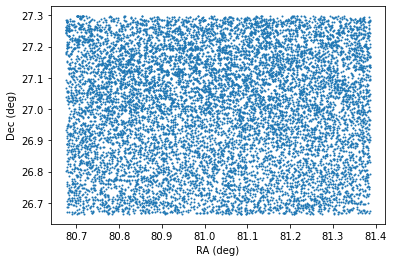

In [51]:
# To get a sense of what is in this catalog, plot the positions
print(f'There are {len(usno)} stars in the usno catalog.')

import matplotlib.pyplot as plt
plt.scatter(usno['RAJ2000'],usno['DEJ2000'],s=1)
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)');

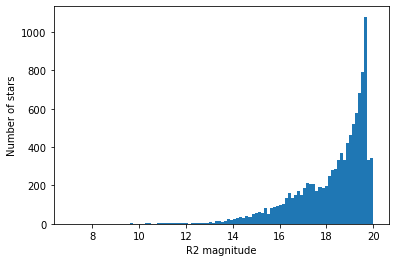

In [52]:
# That's a lot of stars, and we probably don't need the bright foreground ones
# Let's try to limit the number of stars by their magnitude
# We'll use the R2 magnitude 

# Plot the histogram of the R2 magnitudes
plt.hist(usno['R2mag'],bins=100,range=(7,20))
plt.xlabel('R2 magnitude')
plt.ylabel('Number of stars');

There are 1021 stars in the reduced usno catalog.


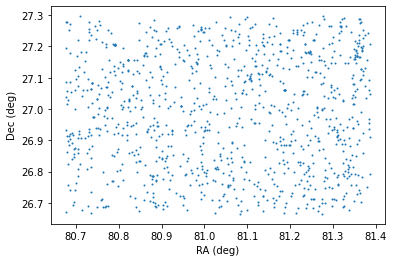

In [53]:
# Based on the histogram, pick a magnitude limit
mag_lim = 

# Keep all the stars that are brighter than the magnitude limit
# Keep in mind that the lower the magnitude, the brighter the star
usno_reduced = usno[usno['R2mag'] < mag_lim]

# Reset the index of the dataframe
usno_reduced = usno_reduced.reset_index(drop=True)

# How many stars are left?
print(f'There are {len(usno_reduced)} stars in the reduced usno catalog.')

# Plot the positions of the remaining stars
plt.scatter(usno_reduced['RAJ2000'],usno_reduced['DEJ2000'],s=1)
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)');

## Step 2: Convert the USNO RA/DEC positions into pixel positions.

We have ra/dec coordinates for a bunch of usno stars in our field, but we need to convert them to pixel coordinates in our images in order to compare. 

Section 4.3 in the lab manual goes over this in more detail. Essentially RA/DEC coordinates are coordinates on a sphere, but our CCD is flat, meaning those coordinates are in a plane. We need to convert from spherical coordinate into our planar x,y coordinates.

First we change RA/DEC to X,Y (sky plane)

$$X = - \frac{\cos{\delta} \sin{(\alpha - \alpha_0)}}{\cos{\delta_0}\cos{\delta}\cos{(\alpha - \alpha_0)} + \sin{\delta} \sin{\delta_0}}$$
  
$$Y = - \frac{\sin{\delta_0} \cos{\delta}\cos{(\alpha - \alpha_0)}-\cos{\delta_0}\sin{\delta}}{\cos{\delta_0}\cos{\delta}\cos{(\alpha - \alpha_0) + \sin{\delta}}\sin{\delta_0}}$$

Where ($\alpha_0$,$\delta_0$) is the center coordinate of the field.

Then we convert X,Y to x,y (detector plane)
$$
x = \left(\frac{f}{p}\right)X + x_0\\
y = \left(\frac{f}{p}\right)Y + y_0
$$

 
Since our projection assumes a unit radius for the celestial sphere, the focal length of our camera, f, is the proportionality constant between our similar triangles. We then just divide by the pixel size, p, to express our values in terms of number of pixels, and add a translation to account for the fact that the center of our CCD is not at the origin. I.E. x0 and y0 are pointing offsets in pixels.  
  
Take a look at this image to visualize the trigonometry of the process to get from X,Y to x,y  

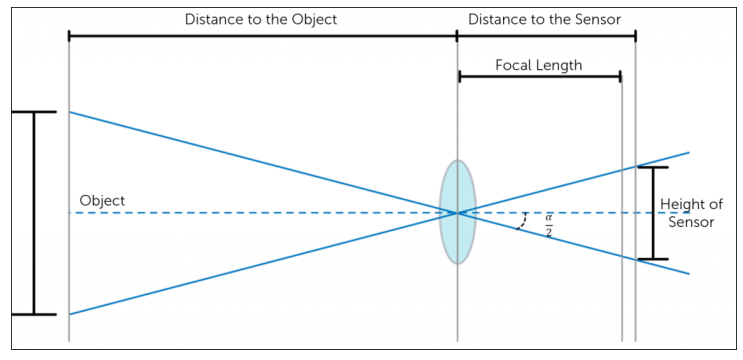

In [7]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
plt.figure(figsize=(13,7))
im = mpimg.imread('../FOV-fig-3-1024x483.png')
plt.imshow(im)
plt.xticks([])
plt.yticks([]);

You can also add in a rotation offset (theta) between the planes as an additional free parameter, but the idea is still the same.

$$
x = \left(\frac{f}{p}\right)\left(X\cos(\theta) - Y\sin(\theta)\right)+ x_0\\
y = \left(\frac{f}{p}\right)\left(X\sin(\theta) + Y\cos(\theta) \right) + y_0
$$

In [54]:
# Define the pixel size and focal length of the detector
pixel_size = 0.009*2 #Remember, the pixels are binned in 2x2 squares
focal_length = 3454

# Define the center of the field and the rotation angle
rotation_angle = -89 #Empirically determined
center_of_field = ['05 24 07.53', '+26 58 50.5']
# The offsets are empirically determined
# Play around with these values to get the best fit
offset_x = 
offset_y = 

# Do the transformation
import sys 
sys.path.append('../')
import ta_funcs as ta
usno_stars = np.vstack((usno_reduced['RAJ2000'].values, usno_reduced['DEJ2000'].values)).T
image_shape = (2048, 2048)
transform_usno_stars = ta.approximate_transform(usno_stars, 
                                                image_shape, 
                                                focal_length, 
                                                pixel_size, 
                                                center_of_field, 
                                                rotation_angle,
                                                offset_x,
                                                offset_y)    

# Add the pixel coordinates to the usno catalog 
usno_reduced['USNO_approx_x'] = transform_usno_stars[:,1]
usno_reduced['USNO_approx_y'] = transform_usno_stars[:,0]

# Notice that some coordinates have a negative value
# These are likely stars that do not land within our field of view
usno_reduced.head()

,USNO-B1.0,RAJ2000,DEJ2000,e_RAJ2000,e_DEJ2000,Epoch,pmRA,pmDE,Ndet,B1mag,R1mag,B2mag,R2mag,Imag,USNO_approx_x,USNO_approx_y
0,1169-0079507,80.676584,26.932414,38.0,144.0,1977.6,-12.0,-6.0,5.0,15.19,13.94,15.23,13.82,12.53,-47.998959,907.302740
1,1169-0079512,80.679150,26.913050,43.0,41.0,1977.6,0.0,0.0,5.0,16.81,15.40,16.64,15.14,14.46,-41.651278,842.308023
2,1169-0079524,80.684453,26.912431,53.0,68.0,1977.6,0.0,0.0,5.0,16.28,15.45,16.38,15.32,14.86,-25.859202,839.915199
3,1169-0079526,80.685492,26.919470,35.0,143.0,1977.6,0.0,0.0,5.0,13.80,11.27,13.14,11.13,9.99,-22.280899,863.422386
4,1169-0079530,80.686164,26.903681,68.0,92.0,1977.6,-8.0,-6.0,5.0,13.84,12.89,13.67,12.55,11.42,-21.341924,810.512990


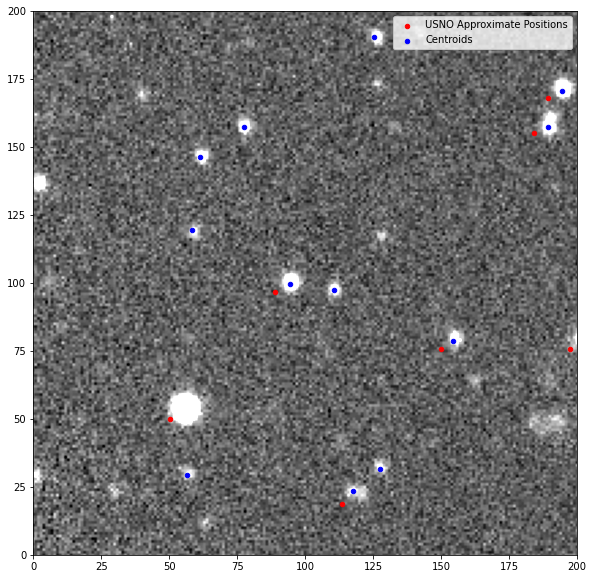

In [55]:
# Lets reopen our image to see if what we did worked
from astropy.io import fits
from astropy.visualization import ZScaleInterval
data = fits.open('Data/26Proserpina/Cleaned/cleaned_20120119.fits')[0].data

# Plot the image
plt.figure(figsize=(10,10))
vmin, vmax = ZScaleInterval().get_limits(data)
plt.imshow(data, cmap='gray', vmin=vmin, vmax=vmax)
plt.scatter(usno_reduced['USNO_approx_x'],usno_reduced['USNO_approx_y'],s=20,color='red',label='USNO Approximate Positions')
plt.scatter(df.x,df.y,s=20,color='blue',label='Centroids')
plt.xlim(0,200)
plt.ylim(0,200)
plt.legend();

# Our transform for RA/DEC to pixel coordinates is an approximation
# We will improve our solution using "plate solving" in the next tutorial 
# For now: 
# - Try to get your USNO pixel positions as close to your centroid as you can 
# - Adjust the magnitude limit to get the number of USNO stars that you want

## Step 3: Crossmatch our centroid catalog to the USNO approximate positions catalog 

In [56]:
# For each star we have, calculate the distance between it and stars in the USNO catalog to find the closest one. 
def distance(x1,y1,x2,y2):
    return 

# Set how close in pixel space the stars need to be to be considered the same star
distance_threshhold =

# Set up the columns from the usno catalog we want to add to our centroid catalog if there's a match
columns = ['USNO-B1.0','RAJ2000','DEJ2000','USNO_approx_x','USNO_approx_y','R2mag','pmRA','pmDE'] 

for ind,row in df.iterrows():
    dist = distance(row.x,row.y,usno_reduced['USNO_approx_x'],usno_reduced['USNO_approx_y'])
    # If it's too far way, set it to NaN
    if np.min(dist) > distance_threshhold:
        df.loc[ind,'Separation'] = np.nan
        for name in columns:
            df.loc[ind,name] = np.nan
    else:
        df.loc[ind,'Separation'] = np.min(dist)
        for name in columns:
            df.loc[ind,name] = usno_reduced.loc[np.argmin(dist),name]

# Rename the columns in our centroid catalog for clarity 
df = df.rename(columns={'x':'Centroid_x','y':'Centroid_y'}) 

# Resort the columns, so they look better
# You can also add in any extra columns you want, like any errors you calculated 👀
df = df[['USNO-B1.0','RAJ2000','DEJ2000','USNO_approx_x','USNO_approx_y','Centroid_x','Centroid_y','Separation','R2mag','pmRA','pmDE']]

# Remember the nan values mean we didn't find a match
df.head()

,USNO-B1.0,RAJ2000,DEJ2000,USNO_approx_x,USNO_approx_y,Centroid_x,Centroid_y,Separation,R2mag,pmRA,pmDE
0,NaN,NaN,NaN,NaN,NaN,56.500570,29.500593,NaN,NaN,NaN,NaN
1,1166-0076363,80.736534,26.668156,113.459731,18.848076,117.501245,23.499652,6.162060,15.69,-22.0,-6.0
2,NaN,NaN,NaN,NaN,NaN,77.501231,157.500363,NaN,NaN,NaN,NaN
3,1167-0076435,80.760864,26.713159,189.216749,168.111517,194.502072,170.505295,5.802139,15.07,0.0,0.0
4,NaN,NaN,NaN,NaN,NaN,125.501442,190.500058,NaN,NaN,NaN,NaN


In [57]:
# We want to remove any stars that don't have a USNO match
# We can do this by removing any rows that have NaN in the USNO-B1.0 column
df = df.dropna(subset=['USNO-B1.0'])
df = df.reset_index(drop=True)

# Now save your catalog
df.to_csv('Data/26Proserpina/Crossmatched/20120119_usno.csv',index=False)
df

,USNO-B1.0,RAJ2000,DEJ2000,USNO_approx_x,USNO_approx_y,Centroid_x,Centroid_y,Separation,R2mag,pmRA,pmDE
0,1166-0076363,80.736534,26.668156,113.459731,18.848076,117.501245,23.499652,6.162060,15.69,-22.0,-6.0
1,1167-0076435,80.760864,26.713159,189.216749,168.111517,194.502072,170.505295,5.802139,15.07,0.0,0.0
2,1166-0076343,80.727825,26.691231,88.933929,96.632143,94.501932,99.503851,6.264931,15.36,0.0,0.0
3,1167-0076431,80.759264,26.709284,184.176449,155.229601,189.501231,157.501373,5.789149,14.77,0.0,0.0
4,1166-0076388,80.748309,26.685384,149.830890,75.842436,154.501686,78.501839,5.374827,15.75,0.0,0.0


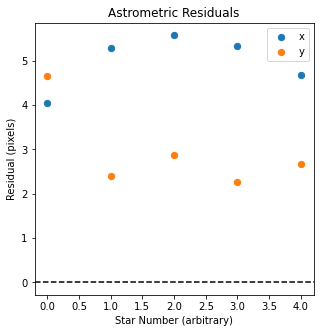

In [58]:
# Let's take a look at our residuals 
plt.figure(figsize=(5,5))
x = np.arange(len(df.Centroid_x))
plt.scatter(x,df.Centroid_x-df.USNO_approx_x,s=40,label='x')
plt.scatter(x,df.Centroid_y-df.USNO_approx_y,s=40,label='y')
plt.axhline(0,color='black',linestyle='--')
plt.xlabel('Star Number (arbitrary)')
plt.ylabel('Residual (pixels)')
plt.title('Astrometric Residuals')
plt.legend();

# In a perfect world, all of our residuals would be close to zero
# But, in this tutorial we only did an *approximate* transformation
# In the next tutorial, we'll do a more accurate transformation using plate solving
